# Lab 1 - Filtering Operations
---

## Imports

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift
from scipy.signal import convolve2d
from Functions import *
from fftwave import fftwave

## Question 1

Point: (5, 9)


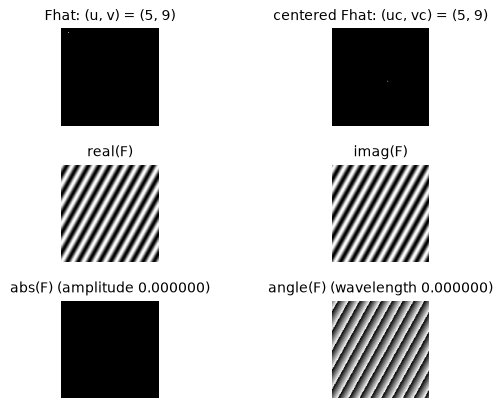

Point: (9, 5)


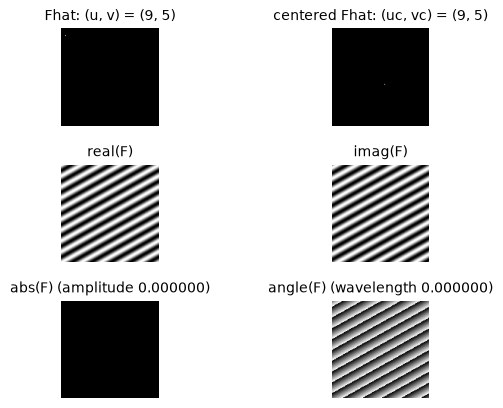

Point: (17, 9)


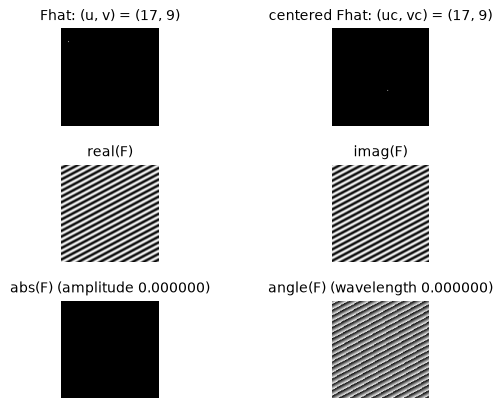

Point: (17, 121)


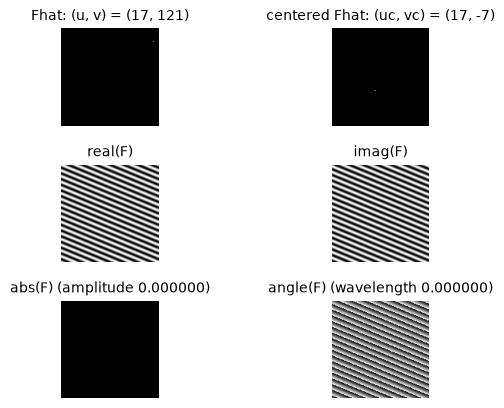

Point: (5, 1)


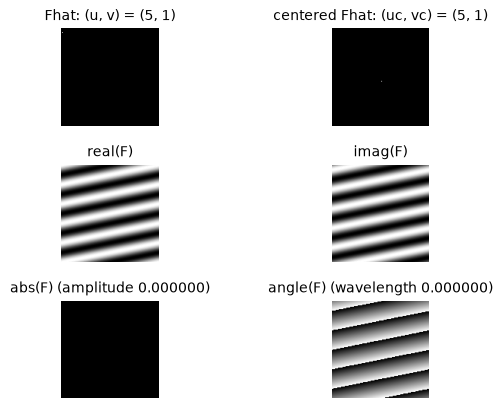

Point: (125, 1)


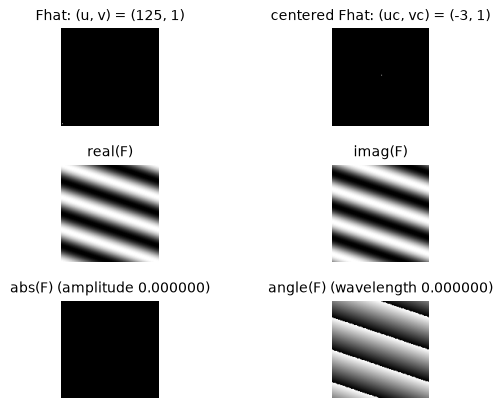

In [ ]:
points = [
    (5, 9),
    (9, 5),
    (17, 9),
    (17, 121),
    (5, 1),
    (125, 1)
]

for (p, q) in points:
    print(f"Point: ({p}, {q})")
    wave = fftwave(p, q)

## Question 2

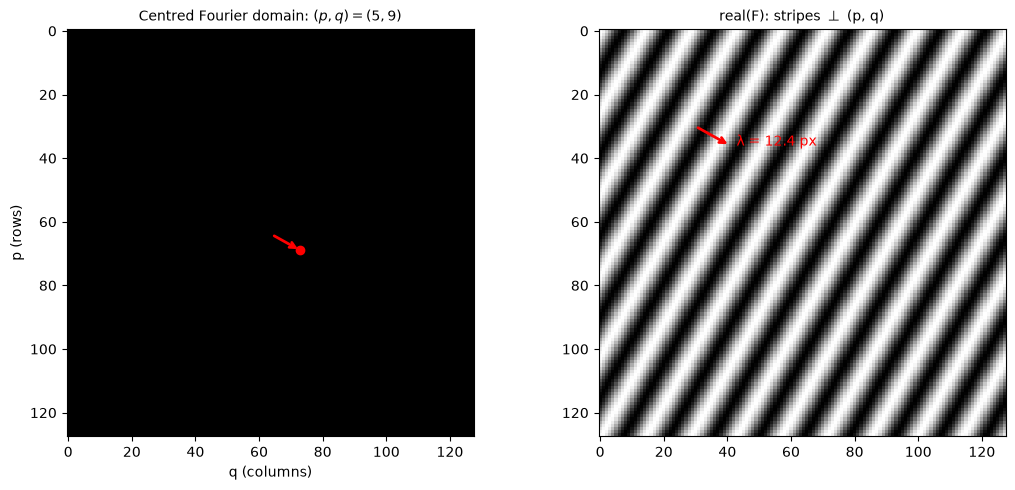

In [11]:
N, p, q = 128, 5, 9
Fhat = np.zeros((N, N)); Fhat[p, q] = 1
F = np.fft.ifft2(Fhat)

pc = p if p < N/2 else p - N
qc = q if q < N/2 else q - N
r = np.hypot(pc, qc)
lam = N / r

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5))

# Left: centred Fourier domain, origin at (N/2, N/2)
a1.imshow(np.fft.fftshift(Fhat), cmap='gray')
c = N // 2
a1.plot(c + qc, c + pc, 'ro', ms=6)
a1.annotate('', xy=(c + qc, c + pc), xytext=(c, c),
            arrowprops=dict(color='red', arrowstyle='->', lw=2))
a1.set_title(rf"Centred Fourier domain: $(p, q) = ({pc}, {qc})$")
a1.set_xlabel("q (columns)"); a1.set_ylabel("p (rows)")

# Right: real part, with an arrow of length one wavelength along (p, q)
a2.imshow(np.real(F), cmap='gray')
x0, y0 = 30, 30
a2.annotate('', xy=(x0 + lam*qc/r, y0 + lam*pc/r), xytext=(x0, y0),
            arrowprops=dict(color='red', arrowstyle='->', lw=2))
a2.text(x0 + lam*qc/r + 2, y0 + lam*pc/r, f"λ = {lam:.1f} px", color='red')
a2.set_title(r"real(F): stripes $\bot$ (p, q)")

plt.tight_layout()
plt.savefig("lab1_q2.png", dpi=300)
plt.show()